In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.preprocessing import LabelEncoder
import seaborn as sns
import seaborn.objects as so


In [9]:
df  = pd.read_excel("C:\\Users\\Adroit\\Desktop\\ASSIGNMENTS\\PROGRAMMING FOR MASSIVE DATA\\Clustering project\\Cleaned_Mall_Customers.xlsx")
df.head(20)

,CustomerID,Gender,Age,Education,Marital Status,Annual Income (k$),Spending Score (1-100)
0,1,M,19,High School,Married,15,39
1,2,M,21,Graduate,Single,15,81
2,3,F,20,Graduate,Married,16,6
3,4,F,23,High School,Unknown,16,77
4,5,F,31,Uneducated,Married,17,40
5,6,F,22,Graduate,Married,17,76
6,7,F,35,Unknown,Married,18,6
7,8,F,23,High School,Unknown,18,94
8,9,M,64,Uneducated,Single,19,3
9,10,F,30,Graduate,Single,19,72


In [10]:
le = LabelEncoder()
df['Gender_encoded'] = le.fit_transform(df['Gender']) # 1 = Male, 0 = Female
df ['Education_encoded'] = le.fit_transform(df['Education'])# 0  = college, 1 = Doctorate, 2 = graduate, 3 = High School, 4 = Post Graduate, 5 = Uneducated, 6 = Unknown 
df ['Marital_Status_encoded'] = le.fit_transform(df['Marital Status']) # 1 = Married, 2 = Single, 3 = Unknown, 4 = Divorced
df.drop(['Gender', 'Education', 'Marital Status'], axis=1, inplace=True)

In [11]:
scaler = StandardScaler()
df[['Age_T','Annual Income (k$)_T','Gender_encoded_T','Education_encoded_T','Marital_Status_encoded_T','Spending_Score_T']] = scaler.fit_transform(df[['Age','Annual Income (k$)','Gender_encoded','Education_encoded','Marital_Status_encoded','Spending Score (1-100)']])
print(df.head(20))

    CustomerID  Age  Annual Income (k$)  Spending Score (1-100)  \
0            1   19                  15                      39   
1            2   21                  15                      81   
2            3   20                  16                       6   
3            4   23                  16                      77   
4            5   31                  17                      40   
5            6   22                  17                      76   
6            7   35                  18                       6   
7            8   23                  18                      94   
8            9   64                  19                       3   
9           10   30                  19                      72   
10          11   67                  19                      14   
11          12   35                  19                      99   
12          13   58                  20                      15   
13          14   24                  20                      7

In [12]:
selected = df[['Age_T','Annual Income (k$)_T','Spending_Score_T','Education_encoded_T']]

In [13]:
def optimize_k_means(data, max_k):
    means = []
    inertias = []
    for k in range (1, max_k):
        kmeans = KMeans (n_clusters = k)
        kmeans.fit(data)
        means.append(k)
        inertias.append(kmeans.inertia_)
    
    fig = plt.subplots(figsize=(10, 5))
    plt.plot(means, inertias, 'o-')
    plt.xlabel('Number of Clusters')
    plt.ylabel('Inertia')
    plt.grid (True)
    plt.show()

c:\Users\Adroit\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Adroit\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Adroit\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Adroit\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Wi

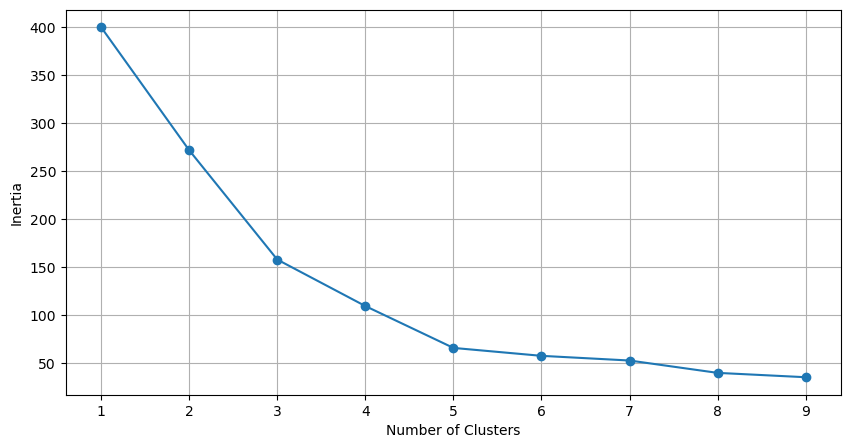

In [14]:
optimize_k_means(df[['Annual Income (k$)_T','Spending_Score_T']], 10)

In [15]:
kmeans = KMeans(n_clusters=5, random_state=1)


In [16]:
kmeans.fit(df[['Annual Income (k$)_T','Spending_Score_T']])

c:\Users\Adroit\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


KMeans(n_clusters=5, random_state=1)

In [17]:
centroids = kmeans.cluster_centers_

In [18]:
df['kmeans_5'] = kmeans.labels_

In [19]:
df

,CustomerID,Age,Annual Income (k$),Spending Score (1-100),Gender_encoded,Education_encoded,Marital_Status_encoded,Age_T,Annual Income (k$)_T,Gender_encoded_T,Education_encoded_T,Marital_Status_encoded_T,Spending_Score_T,kmeans_5
0,1,19,15,39,1,3,1,-1.424569,-1.738999,1.128152,-0.022543,-0.553667,-0.434801,4
1,2,21,15,81,1,2,2,-1.281035,-1.738999,1.128152,-0.586122,0.848022,1.195704,2
2,3,20,16,6,0,2,1,-1.352802,-1.700830,-0.886405,-0.586122,-0.553667,-1.715913,4
3,4,23,16,77,0,3,3,-1.137502,-1.700830,-0.886405,-0.022543,2.249711,1.040418,2
4,5,31,17,40,0,5,1,-0.563369,-1.662660,-0.886405,1.104615,-0.553667,-0.395980,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,196,35,120,79,0,3,1,-0.276302,2.268791,-0.886405,-0.022543,-0.553667,1.118061,1
196,197,45,126,28,0,3,3,0.441365,2.497807,-0.886405,-0.022543,2.249711,-0.861839,3
197,198,32,126,74,1,5,1,-0.491602,2.497807,1.128152,1.104615,-0.553667,0.923953,1
198,199,32,137,18,1,3,1,-0.491602,2.917671,1.128152,-0.022543,-0.553667,-1.250054,3


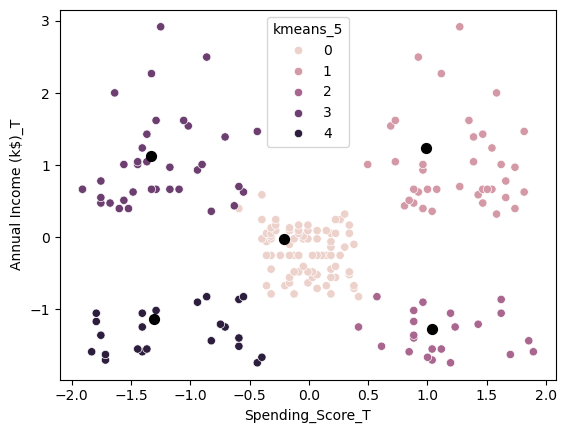

In [21]:

ax = sns.scatterplot(
    data=df,
    y='Annual Income (k$)_T',
    x='Spending_Score_T',
    hue='kmeans_5',


   
)
plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    s=200,
    c='black',
    marker='.',
    label='Centroids'
)
plt.show()

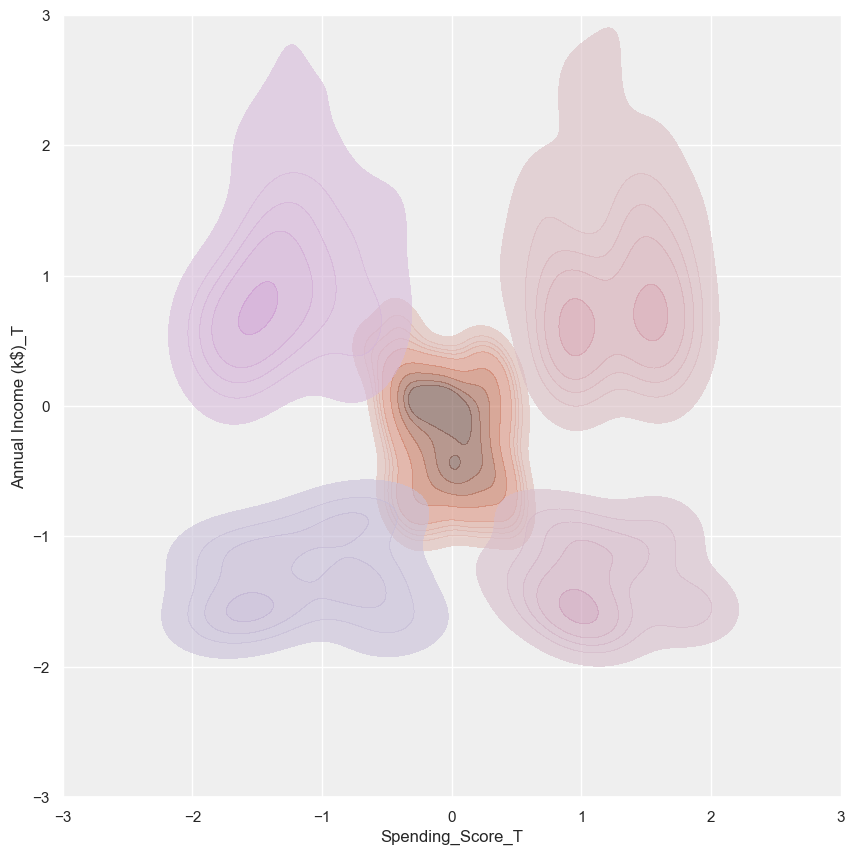

In [22]:
sns.set(rc={'axes.facecolor':'EFEFEF'})
ax = sns.jointplot(x=df['Spending_Score_T'], y=df['Annual Income (k$)_T'],
              cut = 2, hue=df['kmeans_5'],
        
              xlim=[-3,3], ylim=[-3,3],
              kind='kde', fill=True,
              height=10, ratio=6,
              joint_kws = dict(alpha=0.6),
              marginal_kws=dict(fill=True),
              legend=False)
ax.ax_marg_x.remove()
ax.ax_marg_y.remove()
plt.show()

In [23]:
df['kmeans_5'].value_counts()

kmeans_5
0    80
1    39
3    36
4    23
2    22
Name: count, dtype: int64

In [25]:
df['kmeans_5'] = df['kmeans_5'].astype('int64')

In [26]:
df.groupby('kmeans_5').median(numeric_only=True)

,CustomerID,Age,Annual Income (k$),Spending Score (1-100),Gender_encoded,Education_encoded,Marital_Status_encoded,Age_T,Annual Income (k$)_T,Gender_encoded_T,Education_encoded_T,Marital_Status_encoded_T,Spending_Score_T
kmeans_5,,,,,,,,,,,,,
0,85.5,46.5,54.0,50.0,0.0,2.0,1.0,0.549015,-0.250391,-0.886405,-0.586122,-0.553667,-0.007764
1,162.0,32.0,79.0,83.0,0.0,3.0,1.0,-0.491602,0.703844,-0.886405,-0.022543,-0.553667,1.273347
2,23.0,23.5,24.5,77.0,0.0,3.0,1.0,-1.101619,-1.376390,-0.886405,-0.022543,-0.553667,1.040418
3,164.0,41.5,83.0,16.0,1.0,3.0,1.0,0.190182,0.856522,1.128152,-0.022543,-0.553667,-1.327697
4,23.0,46.0,25.0,17.0,0.0,3.0,1.0,0.513132,-1.357305,-0.886405,-0.022543,-0.553667,-1.288876


In [27]:
#Interpretation
# 0 = mid income, moderate spending
# 1 = low income, high spending
# 2 = high income, low spending
# 3 = high income, high spending
# 4 = low income, low spending
# younger people are likely to be low income high spenders
# men are likely to be high income low spenders
# majority of people are mid income moderate spenders
# the smallest group are the low income high spenders
# most mid income moderate spenders are educated to the graduate level

